In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [2]:
df = pd.read_csv("../data/processed/final_ml_dataset.csv")

In [3]:
df.apply(lambda col: col.duplicated().sum())

product_id                         107189
product_name                       107189
year                               109004
month                              108997
month_number                       108997
monthly_revenue                     21165
monthly_quantity                   108900
monthly_transactions               108989
average_discount_pct               107583
maximum_discount                   108978
total_discount_amount               57060
pct_transactions_discount_gt_10    108933
pct_transactions_discount_gt_15    108940
total_transactions                 108989
average_selling_price               21486
minimum_selling_price               92832
maximum_selling_price               92014
price_range                         62057
non_discounted_revenue             106369
discounted_revenue                  21716
discounted_quantity_sold           108904
discounted_orders                  108989
unique_customers                   108989
revenue_per_customer              

In [4]:
df.shape

(109009, 56)

In [5]:
df.columns

Index(['product_id', 'product_name', 'year', 'month', 'month_number',
       'monthly_revenue', 'monthly_quantity', 'monthly_transactions',
       'average_discount_pct', 'maximum_discount', 'total_discount_amount',
       'pct_transactions_discount_gt_10', 'pct_transactions_discount_gt_15',
       'total_transactions', 'average_selling_price', 'minimum_selling_price',
       'maximum_selling_price', 'price_range', 'non_discounted_revenue',
       'discounted_revenue', 'discounted_quantity_sold', 'discounted_orders',
       'unique_customers', 'revenue_per_customer', 'units_per_customer',
       'category_revenue_share', 'category_unit_share', 'total_profit',
       'average_profit', 'market_share', 'lag_1_revenue', 'lag_2_revenue',
       'lag_3_revenue', 'lag_12_revenue', 'lag_1_quantity', 'lag_2_quantity',
       'lag_3_quantity', 'lag_12_quantity', 'lag_1_transactions',
       'lag_2_transactions', 'lag_3_transactions', 'lag_12_transactions',
       'moving_avg_3_month', 'moving_av

In [6]:
df.isnull().sum()

product_id                             0
product_name                           0
year                                   0
month                                  0
month_number                           0
monthly_revenue                        0
monthly_quantity                       0
monthly_transactions                   0
average_discount_pct                   0
maximum_discount                       0
total_discount_amount                  0
pct_transactions_discount_gt_10        0
pct_transactions_discount_gt_15        0
total_transactions                     0
average_selling_price                  0
minimum_selling_price                  0
maximum_selling_price                  0
price_range                            0
non_discounted_revenue                 0
discounted_revenue                     0
discounted_quantity_sold               0
discounted_orders                      0
unique_customers                       0
revenue_per_customer                   0
units_per_custom

In [7]:
rolling_features = ['lag_1_revenue',
       'lag_2_revenue', 'lag_3_revenue', 'lag_12_revenue', 'lag_1_quantity',
       'lag_2_quantity', 'lag_3_quantity', 'lag_12_quantity',
       'lag_1_transactions', 'lag_2_transactions', 'lag_3_transactions',
       'lag_12_transactions']

In [8]:
for col in rolling_features:
    null_cols = df[col].isnull().sum()
    print(col, null_cols)

lag_1_revenue 1820
lag_2_revenue 3640
lag_3_revenue 5460
lag_12_revenue 21840
lag_1_quantity 1820
lag_2_quantity 3640
lag_3_quantity 5460
lag_12_quantity 21840
lag_1_transactions 1820
lag_2_transactions 3640
lag_3_transactions 5460
lag_12_transactions 21840


In [9]:
df[df['product_id'] == 'P0001'][['product_id','year','month','monthly_revenue','lag_1_revenue','lag_2_revenue','lag_3_revenue','lag_12_revenue','next_monthly_revenue']].tail(15)

,product_id,year,month,monthly_revenue,lag_1_revenue,lag_2_revenue,lag_3_revenue,lag_12_revenue,next_monthly_revenue
82666,P0001,2024,October,1425.60,2389.72,2516.45,2232.92,3232.41,937.73
84984,P0001,2024,November,937.73,1425.60,2389.72,2516.45,288.29,2597.23
87074,P0001,2024,December,2597.23,937.73,1425.60,2389.72,1889.18,2941.49
87219,P0001,2025,January,2941.49,2597.23,937.73,1425.60,2796.29,690.62
89402,P0001,2025,February,690.62,2941.49,2597.23,937.73,900.77,2771.47
91642,P0001,2025,March,2771.47,690.62,2941.49,2597.23,2181.17,2730.28
92845,P0001,2025,April,2730.28,2771.47,690.62,2941.49,1143.12,1998.48
95096,P0001,2025,May,1998.48,2730.28,2771.47,690.62,675.31,1001.09
97305,P0001,2025,June,1001.09,1998.48,2730.28,2771.47,2212.84,826.85
99435,P0001,2025,July,826.85,1001.09,1998.48,2730.28,2232.92,742.90


In [10]:
df[df['product_id'] == 'P0001'][['product_id', 'year', 'month', 'monthly_revenue', 'moving_avg_3_month']]

,product_id,year,month,monthly_revenue,moving_avg_3_month
34,P0001,2021,January,1960.47,NaN
2293,P0001,2021,February,1248.72,NaN
4532,P0001,2021,March,3088.80,2099.330000
5631,P0001,2021,April,593.46,1643.660000
7803,P0001,2021,May,2042.83,1908.363333
9989,P0001,2021,June,1021.69,1219.326667
12238,P0001,2021,July,607.73,1224.083333
14526,P0001,2021,August,1340.07,989.830000
14657,P0001,2021,September,2598.81,1515.536667
16775,P0001,2021,October,1604.59,1847.823333


In [11]:
df = df.sort_values(['product_id', 'year', 'month_number'])

expected_lag_1 = (
    df.groupby('product_id')['monthly_revenue']
      .shift(1)
)

expected_lag_2 = (
    df.groupby('product_id')['monthly_revenue']
      .shift(2)
)

In [12]:
expected_target = (
    df.groupby('product_id')['monthly_revenue']
      .shift(-1)
)

In [13]:
(df['next_monthly_revenue'].fillna(-999) == expected_target.fillna(-999)).all()

np.True_

In [14]:
(df['lag_2_revenue'].fillna(-999) == expected_lag_2.fillna(-999)).all()

np.True_

In [15]:
df['lag_2_revenue'].fillna(-999)

34         -999.00
2293       -999.00
4532       1960.47
5631       1248.72
7803       3088.80
            ...   
101306    69997.50
103549    57375.00
103590    69390.00
105863    25987.50
107885    67837.50
Name: lag_2_revenue, Length: 109009, dtype: float64

In [16]:
df['lag_3_revenue'].isna().sum()

np.int64(5460)

##### Correlation Analysis

In [17]:
numeric_cols = df.select_dtypes(include='number').columns
feature_cols = numeric_cols.drop('next_monthly_revenue')

corr_matrix = df[feature_cols].corr()

In [18]:
corr_matrix

,year,month_number,monthly_revenue,monthly_quantity,monthly_transactions,average_discount_pct,maximum_discount,total_discount_amount,pct_transactions_discount_gt_10,pct_transactions_discount_gt_15,...,moving_stdev_3_month,moving_stdev_6_month,momentum,month_over_month,year_on_year,is_quarter_end,is_year_end,trend_year,sin_month,cos_month
year,1.000000,0.000044,-0.000993,-0.001167,-0.002235,-0.000850,-0.000074,-0.002638,-0.000957,-0.000410,...,-0.000736,0.000034,-0.020029,0.002333,0.007565,5.045599e-05,0.000068,1.000000,0.000032,-0.000038
month_number,0.000044,1.000000,0.000405,0.008398,0.012872,-0.000951,0.001261,0.001312,0.001054,-0.001431,...,-0.001606,-0.001756,-0.003803,-0.000436,-0.005025,2.048609e-01,0.480445,0.000044,-0.764423,0.204729
monthly_revenue,-0.000993,0.000405,1.000000,-0.066119,0.161782,-0.141918,-0.089201,0.928278,-0.097242,-0.156618,...,0.816339,0.869845,0.050426,0.058028,0.056772,-1.376693e-03,-0.000282,-0.000993,-0.001632,-0.002722
monthly_quantity,-0.001167,0.008398,-0.066119,1.000000,0.595159,-0.399433,-0.355773,-0.127823,-0.473225,-0.290598,...,-0.125263,-0.146502,0.232313,0.257976,0.262900,7.123564e-04,0.004086,-0.001167,-0.012083,-0.008078
monthly_transactions,-0.002235,0.012872,0.161782,0.595159,1.000000,-0.006645,0.103225,0.193190,-0.009720,-0.006652,...,0.024526,0.009822,0.312991,0.330737,0.335969,1.071329e-03,0.008029,-0.002235,-0.017320,-0.014563
average_discount_pct,-0.000850,-0.000951,-0.141918,-0.399433,-0.006645,1.000000,0.960080,0.070253,0.932289,0.919212,...,-0.134914,-0.146591,-0.002882,-0.014526,-0.012132,2.016744e-04,-0.000306,-0.000850,0.000746,0.000384
maximum_discount,-0.000074,0.001261,-0.089201,-0.355773,0.103225,0.960080,1.000000,0.113519,0.904488,0.893402,...,-0.105518,-0.114475,0.032513,0.024497,0.026682,-1.046953e-05,0.000761,-0.000074,-0.001192,-0.002082
total_discount_amount,-0.002638,0.001312,0.928278,-0.127823,0.193190,0.070253,0.113519,1.000000,0.103274,0.026508,...,0.757864,0.807511,0.062640,0.065687,0.065526,-1.083340e-03,-0.000130,-0.002638,-0.002111,-0.003715
pct_transactions_discount_gt_10,-0.000957,0.001054,-0.097242,-0.473225,-0.009720,0.932289,0.904488,0.103274,1.000000,0.816687,...,-0.093602,-0.101256,-0.003561,-0.015671,-0.014478,6.498250e-04,0.001341,-0.000957,0.000139,0.001190
pct_transactions_discount_gt_15,-0.000410,-0.001431,-0.156618,-0.290598,-0.006652,0.919212,0.893402,0.026508,0.816687,1.000000,...,-0.148862,-0.162415,-0.003477,-0.010018,-0.007947,7.700158e-04,0.000849,-0.000410,0.001237,-0.000060


In [19]:
target_corr = (df[feature_cols].corrwith(df['next_monthly_revenue']).sort_values(ascending=False))

In [20]:
target_corr

moving_avg_12_month                0.899326
maximum_selling_price              0.898690
revenue_per_customer               0.893094
average_selling_price              0.893070
moving_avg_6_month                 0.892207
moving_avg_3_month                 0.878390
minimum_selling_price              0.875292
moving_stdev_6_month               0.853300
price_range                        0.844500
lag_2_revenue                      0.828857
lag_3_revenue                      0.826893
lag_1_revenue                      0.823809
lag_12_revenue                     0.823035
market_share                       0.821111
monthly_revenue                    0.819654
discounted_revenue                 0.813838
average_profit                     0.789456
moving_stdev_3_month               0.781319
total_discount_amount              0.760160
total_profit                       0.723054
category_revenue_share             0.502216
non_discounted_revenue             0.448621
category_unit_share             

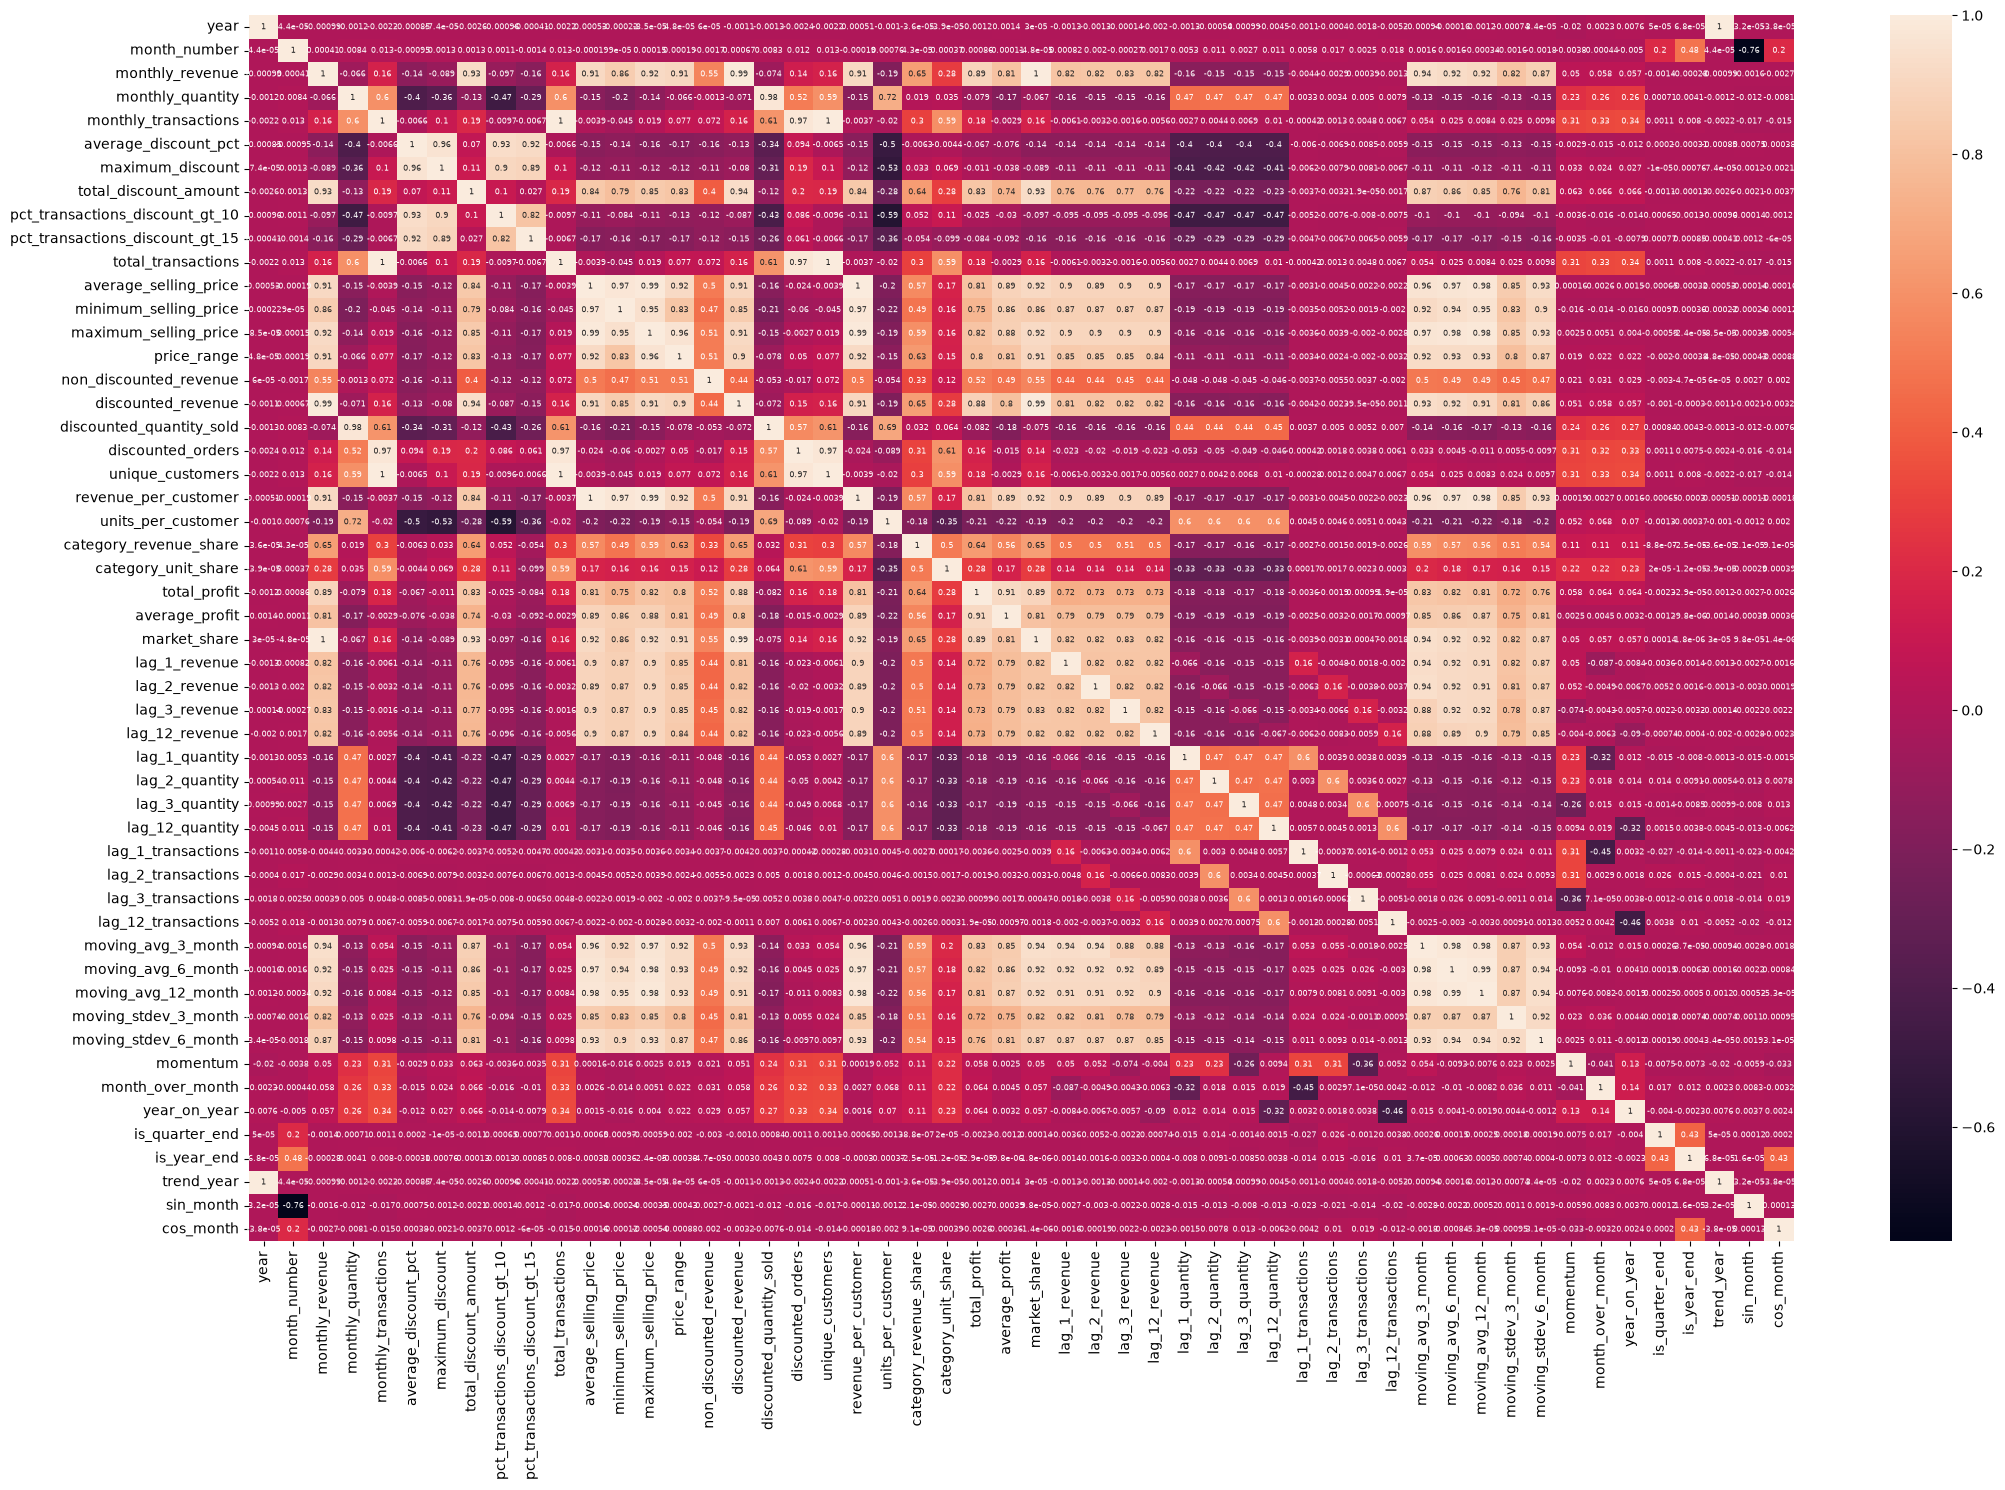

In [21]:
plt.figure(figsize=[22,15])
sns.heatmap(df[feature_cols].corr(), annot=True, annot_kws={'size': 6})
plt.tight_layout()
plt.show()

##### Breaking the Dataset into different sections

1) Revenue/Historical Features

In [22]:
historical_features = ['monthly_revenue', 'monthly_quantity', 'monthly_transactions', 'lag_1_revenue', 'lag_2_revenue',
                       'lag_3_revenue', 'lag_12_revenue', 'lag_1_quantity', 'lag_2_quantity',
                       'lag_3_quantity', 'lag_12_quantity', 'lag_1_transactions',
                       'lag_2_transactions', 'lag_3_transactions', 'lag_12_transactions',
                       'moving_avg_3_month', 'moving_avg_6_month', 'moving_avg_12_month',
                       'moving_stdev_3_month', 'moving_stdev_6_month', 'momentum']

In [23]:
historical_features_corr = df[historical_features].corr().stack().reset_index()
historical_features_corr.columns = ['Feature A', 'Feature B', 'Correlation']
historical_features_corr = historical_features_corr[historical_features_corr['Feature A'] != historical_features_corr['Feature B']]

In [24]:
historical_features_corr

,Feature A,Feature B,Correlation
1,monthly_revenue,monthly_quantity,-0.066119
2,monthly_revenue,monthly_transactions,0.161782
3,monthly_revenue,lag_1_revenue,0.819654
4,monthly_revenue,lag_2_revenue,0.823809
5,monthly_revenue,lag_3_revenue,0.828857
...,...,...,...
435,momentum,moving_avg_3_month,0.054160
436,momentum,moving_avg_6_month,-0.009331
437,momentum,moving_avg_12_month,-0.007553
438,momentum,moving_stdev_3_month,0.023129


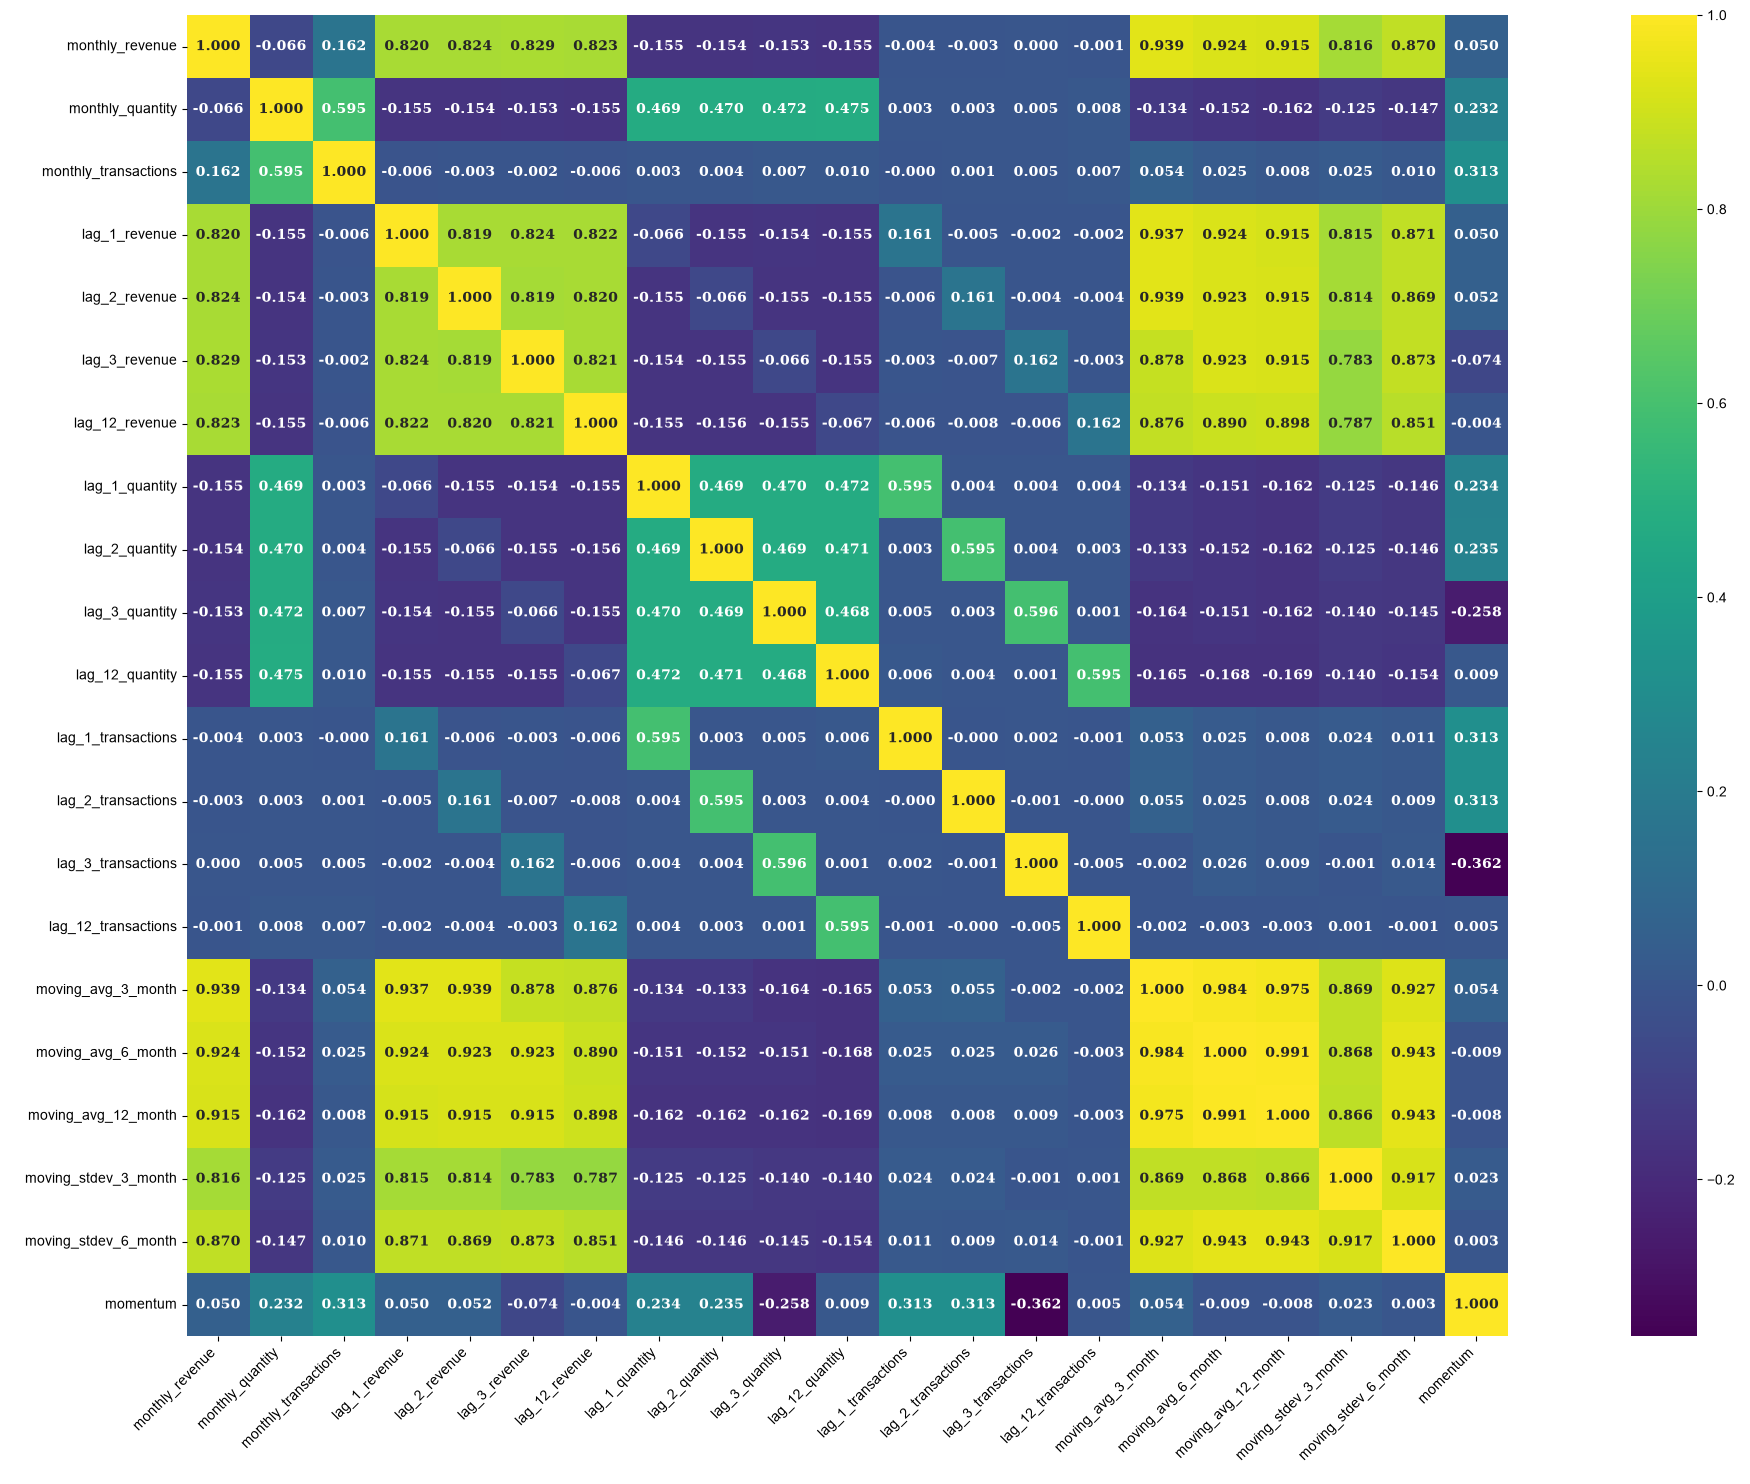

In [25]:
plt.figure(figsize=[25,15])
sns.heatmap(df[historical_features].corr(), annot=True, fmt='.3f', square=True, cmap='viridis', annot_kws={'family': 'serif', 'size': 10, 'weight': 'bold'})
sns.set(font_scale=1)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

2) Price & Discount Features

In [26]:
price_and_discount_features = ['monthly_revenue', 'monthly_quantity',
       'monthly_transactions', 'average_discount_pct', 'maximum_discount',
       'total_discount_amount', 'pct_transactions_discount_gt_10',
       'pct_transactions_discount_gt_15', 'total_transactions',
       'average_selling_price', 'minimum_selling_price',
       'maximum_selling_price', 'price_range', 'non_discounted_revenue',
       'discounted_revenue', 'discounted_quantity_sold', 'discounted_orders']

In [27]:
price_and_discount_features_corr = df[price_and_discount_features].corr().stack().reset_index()
price_and_discount_features_corr.columns = ['Feature A', 'Feature B', 'Correlation']
price_and_discount_features_corr = price_and_discount_features_corr[price_and_discount_features_corr['Feature A'] != price_and_discount_features_corr['Feature B']]

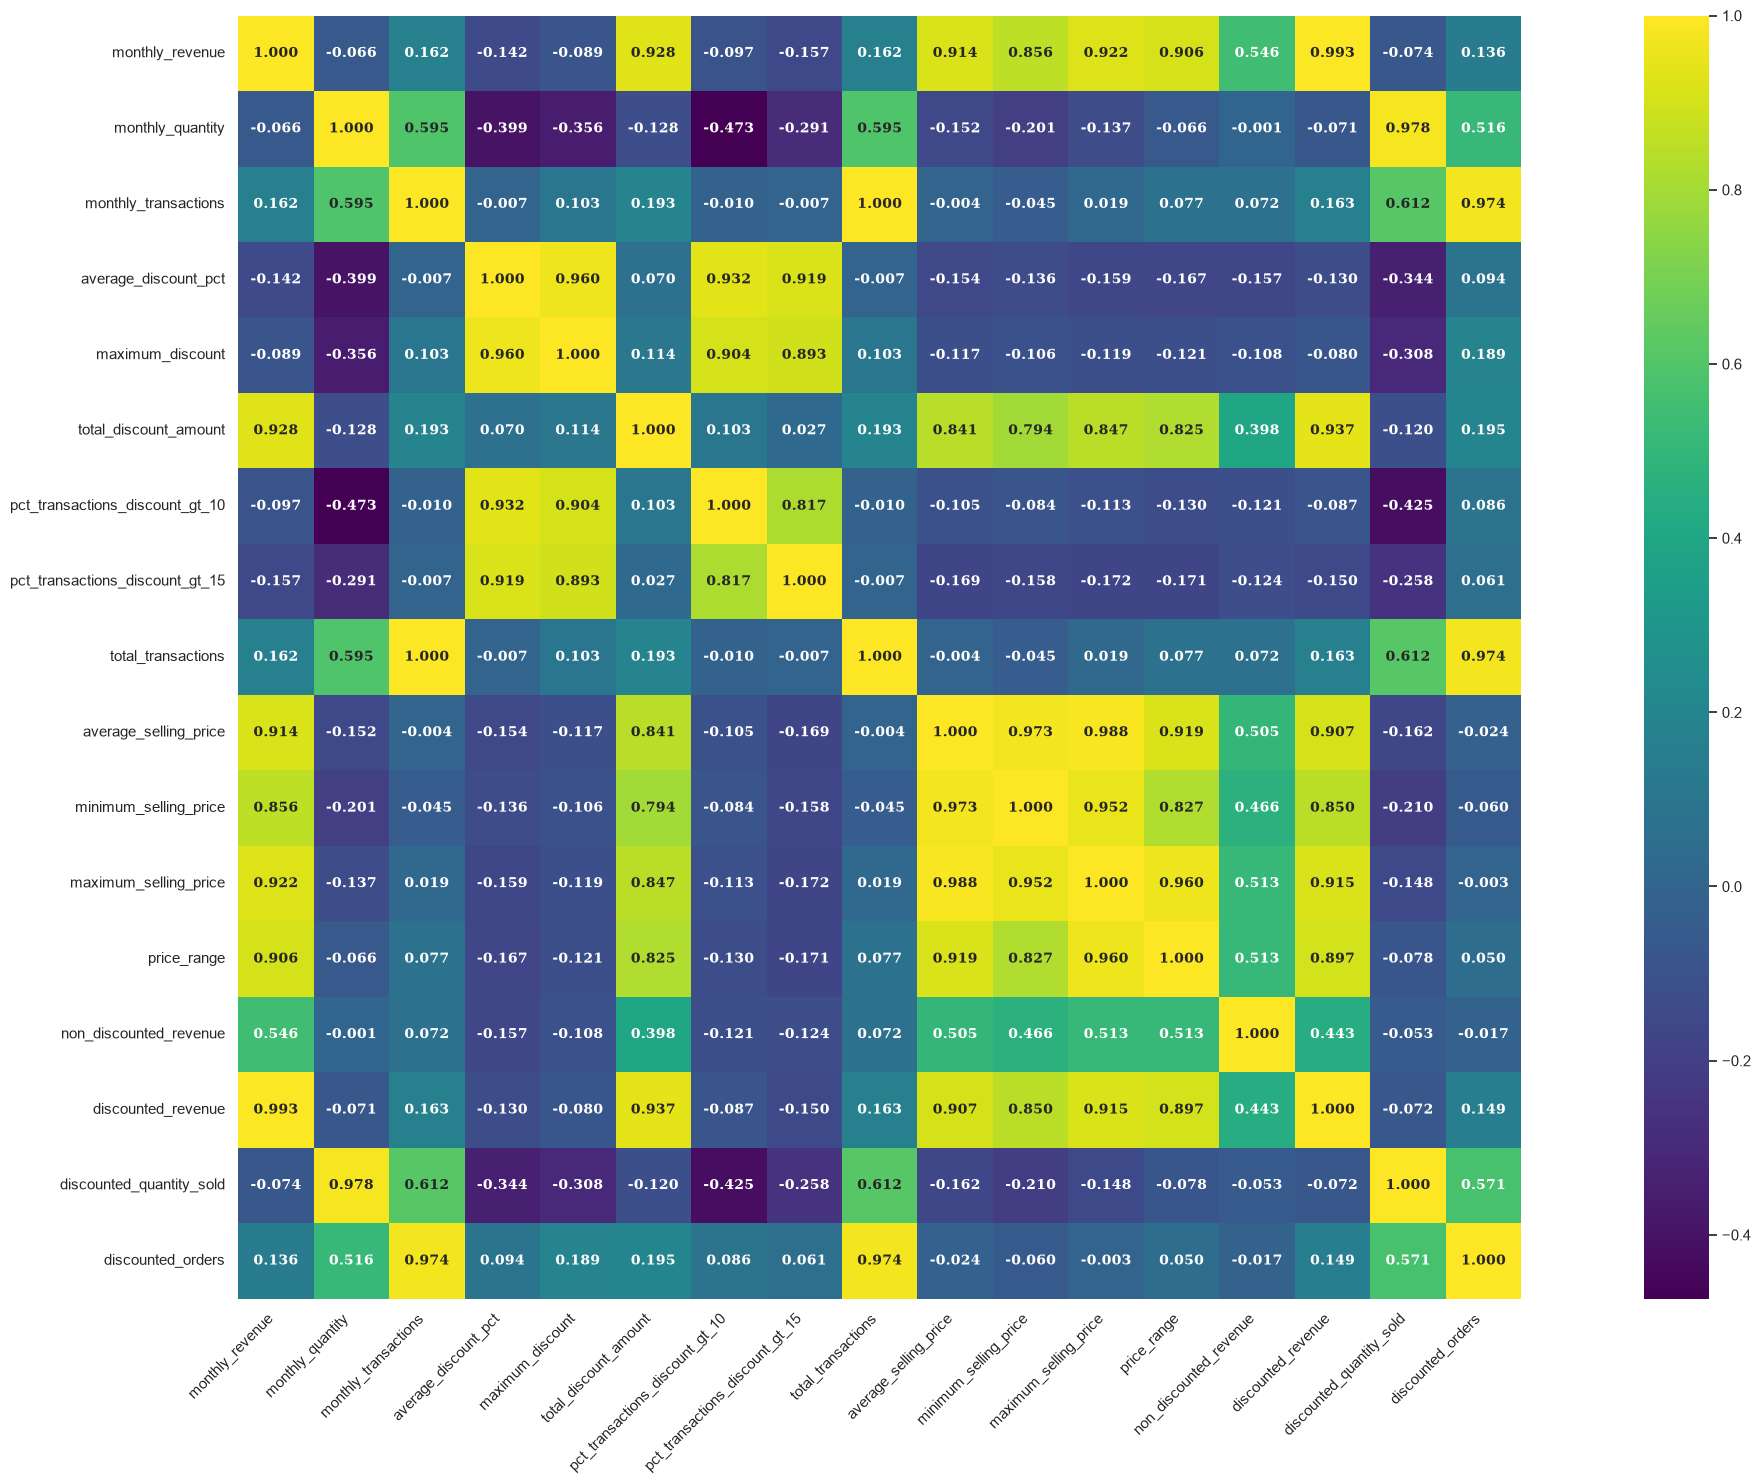

In [28]:
plt.figure(figsize=[25,15])
sns.heatmap(df[price_and_discount_features].corr(), annot=True, fmt='.3f', square=True, cmap='viridis', annot_kws={'family': 'serif', 'size': 10, 'weight': 'bold'})
sns.set(font_scale=1)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

3) Customer/Profitability/Market Features

In [29]:
market_features = ['monthly_revenue', 'monthly_quantity',
       'monthly_transactions', 'unique_customers', 'revenue_per_customer', 'units_per_customer',
       'category_revenue_share', 'category_unit_share', 'total_profit',
       'average_profit', 'market_share']

In [30]:
df[market_features].corr()

,monthly_revenue,monthly_quantity,monthly_transactions,unique_customers,revenue_per_customer,units_per_customer,category_revenue_share,category_unit_share,total_profit,average_profit,market_share
monthly_revenue,1.000000,-0.066119,0.161782,0.161614,0.914175,-0.188654,0.649685,0.277311,0.891523,0.812425,0.998767
monthly_quantity,-0.066119,1.000000,0.595159,0.594848,-0.151503,0.720744,0.018509,0.034852,-0.079279,-0.173458,-0.066679
monthly_transactions,0.161782,0.595159,1.000000,0.999679,-0.003728,-0.019729,0.297011,0.588926,0.179092,-0.002858,0.161279
unique_customers,0.161614,0.594848,0.999679,1.000000,-0.003890,-0.020378,0.296900,0.588804,0.178866,-0.002946,0.161112
revenue_per_customer,0.914175,-0.151503,-0.003728,-0.003890,1.000000,-0.194982,0.566681,0.170787,0.808702,0.886780,0.915336
units_per_customer,-0.188654,0.720744,-0.019729,-0.020378,-0.194982,1.000000,-0.176233,-0.351216,-0.213598,-0.221519,-0.189425
category_revenue_share,0.649685,0.018509,0.297011,0.296900,0.566681,-0.176233,1.000000,0.504802,0.640440,0.555085,0.651070
category_unit_share,0.277311,0.034852,0.588926,0.588804,0.170787,-0.351216,0.504802,1.000000,0.280467,0.165844,0.278386
total_profit,0.891523,-0.079279,0.179092,0.178866,0.808702,-0.213598,0.640440,0.280467,1.000000,0.911577,0.890456
average_profit,0.812425,-0.173458,-0.002858,-0.002946,0.886780,-0.221519,0.555085,0.165844,0.911577,1.000000,0.813507


In [31]:
market_features_corr = df[market_features].corr().stack().reset_index()
market_features_corr.columns = ['Feature A', 'Feature B', 'Correlation']
market_features_corr = market_features_corr[market_features_corr['Feature A'] != market_features_corr['Feature B']]

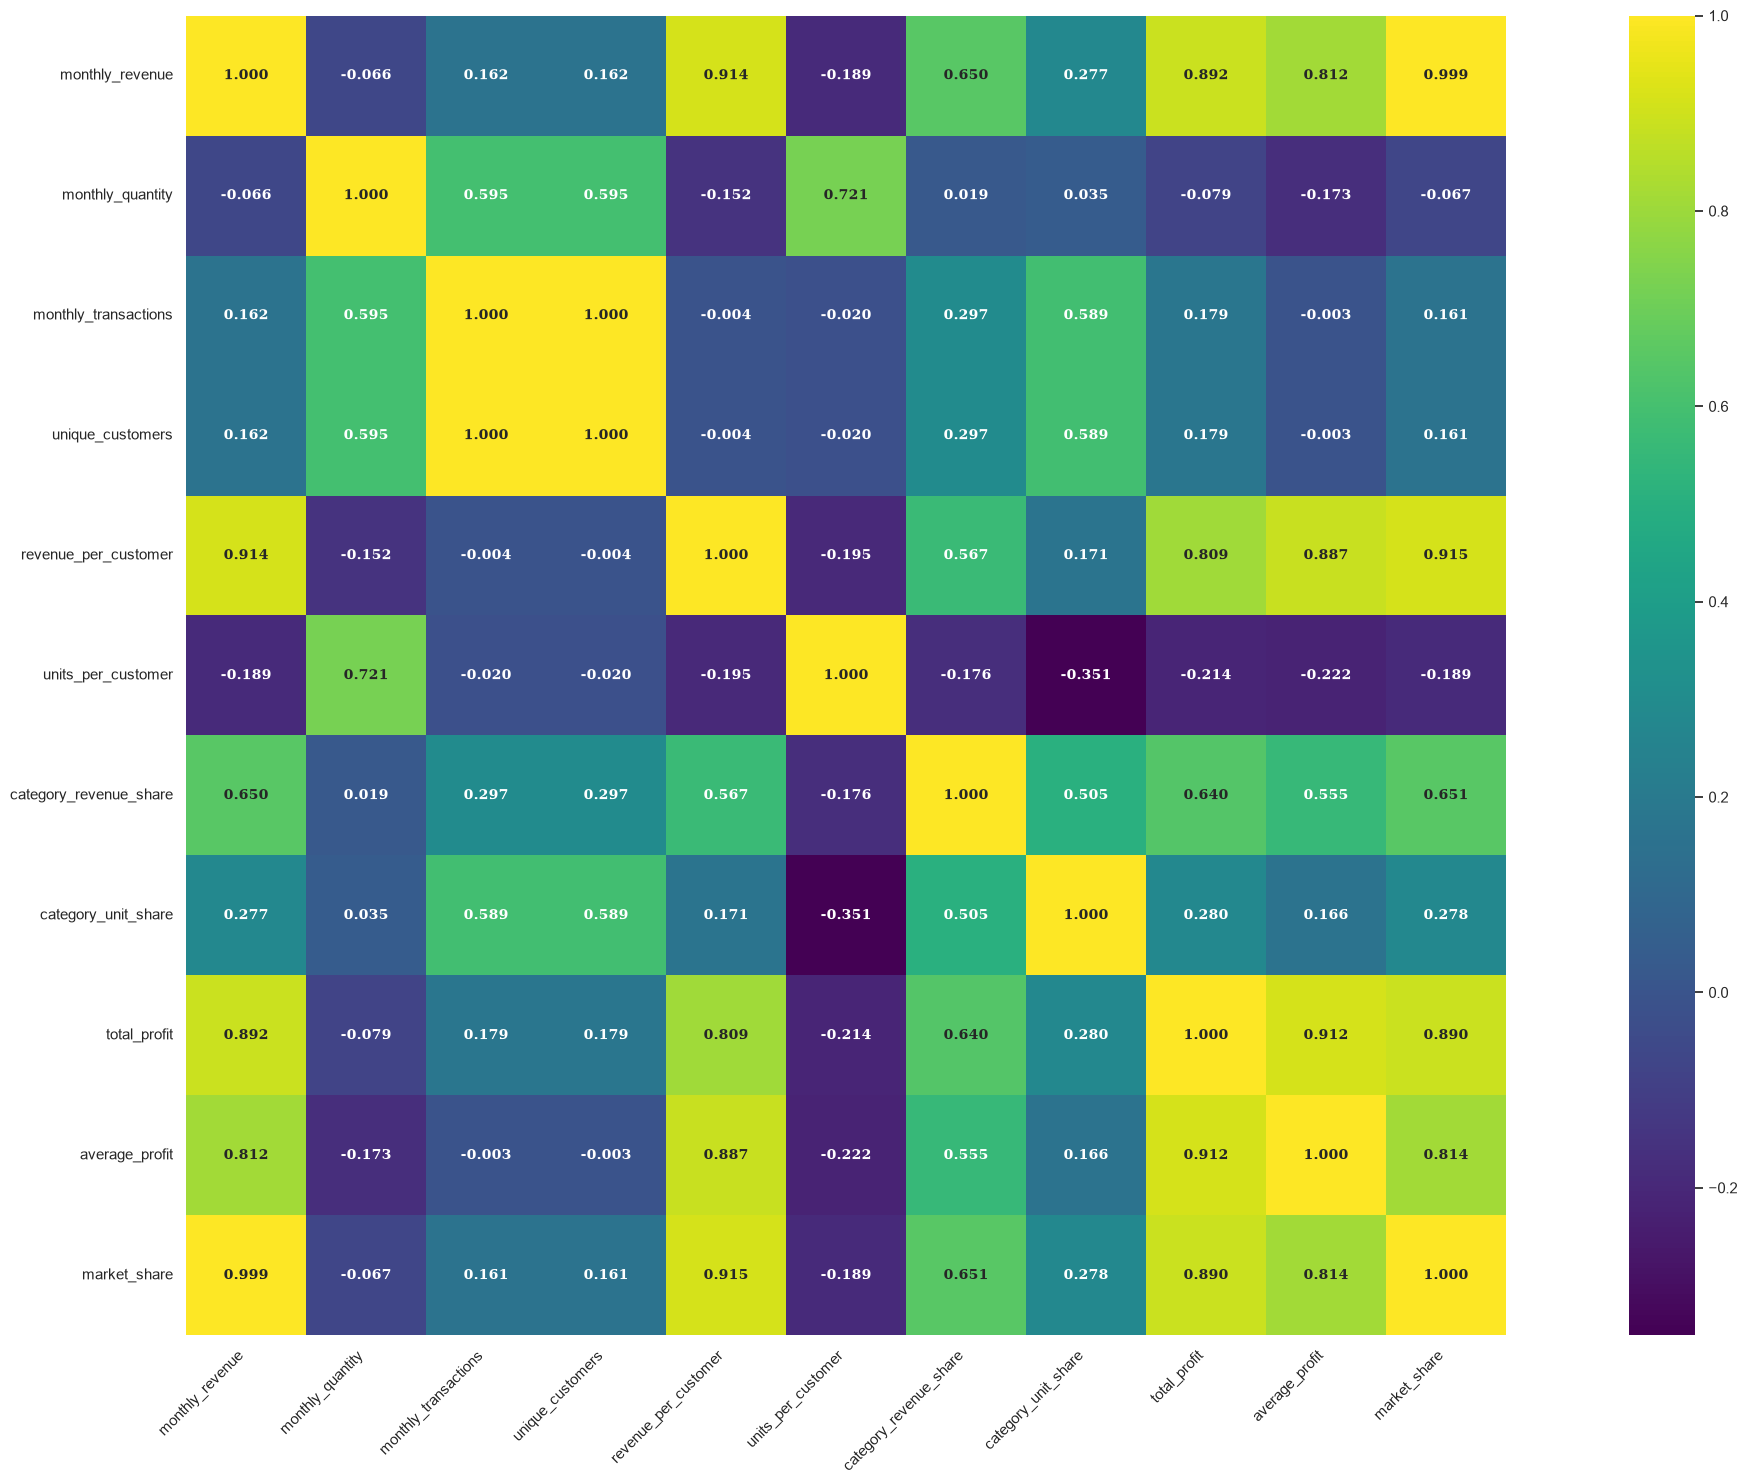

In [32]:
plt.figure(figsize=[25,15])
sns.heatmap(df[market_features].corr(), annot=True, fmt='.3f', square=True, cmap='viridis', annot_kws={'family': 'serif', 'size': 10, 'weight': 'bold'})
sns.set(font_scale=1)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

4) Calendar Features

In [33]:
calendar_features = ['monthly_revenue', 'monthly_quantity',
       'monthly_transactions', 'month_over_month', 'year_on_year', 'is_quarter_end', 'is_year_end',
       'trend_year', 'sin_month', 'cos_month']

In [34]:
df[calendar_features].corr()

,monthly_revenue,monthly_quantity,monthly_transactions,month_over_month,year_on_year,is_quarter_end,is_year_end,trend_year,sin_month,cos_month
monthly_revenue,1.000000,-0.066119,0.161782,0.058028,0.056772,-0.001377,-0.000282,-0.000993,-0.001632,-0.002722
monthly_quantity,-0.066119,1.000000,0.595159,0.257976,0.262900,0.000712,0.004086,-0.001167,-0.012083,-0.008078
monthly_transactions,0.161782,0.595159,1.000000,0.330737,0.335969,0.001071,0.008029,-0.002235,-0.017320,-0.014563
month_over_month,0.058028,0.257976,0.330737,1.000000,0.136150,0.017341,0.011805,0.002333,0.008288,-0.003172
year_on_year,0.056772,0.262900,0.335969,0.136150,1.000000,-0.003997,-0.002276,0.007565,0.003733,0.002445
is_quarter_end,-0.001377,0.000712,0.001071,0.017341,-0.003997,1.000000,0.426437,0.000050,0.000120,0.000201
is_year_end,-0.000282,0.004086,0.008029,0.011805,-0.002276,0.426437,1.000000,0.000068,0.000016,0.426475
trend_year,-0.000993,-0.001167,-0.002235,0.002333,0.007565,0.000050,0.000068,1.000000,0.000032,-0.000038
sin_month,-0.001632,-0.012083,-0.017320,0.008288,0.003733,0.000120,0.000016,0.000032,1.000000,0.000127
cos_month,-0.002722,-0.008078,-0.014563,-0.003172,0.002445,0.000201,0.426475,-0.000038,0.000127,1.000000


In [35]:
calendar_features_corr = df[calendar_features].corr().stack().reset_index()
calendar_features_corr.columns = ['Feature A', 'Feature B', 'Correlation']
calendar_features_corr = calendar_features_corr[calendar_features_corr['Feature A'] != calendar_features_corr['Feature B']]

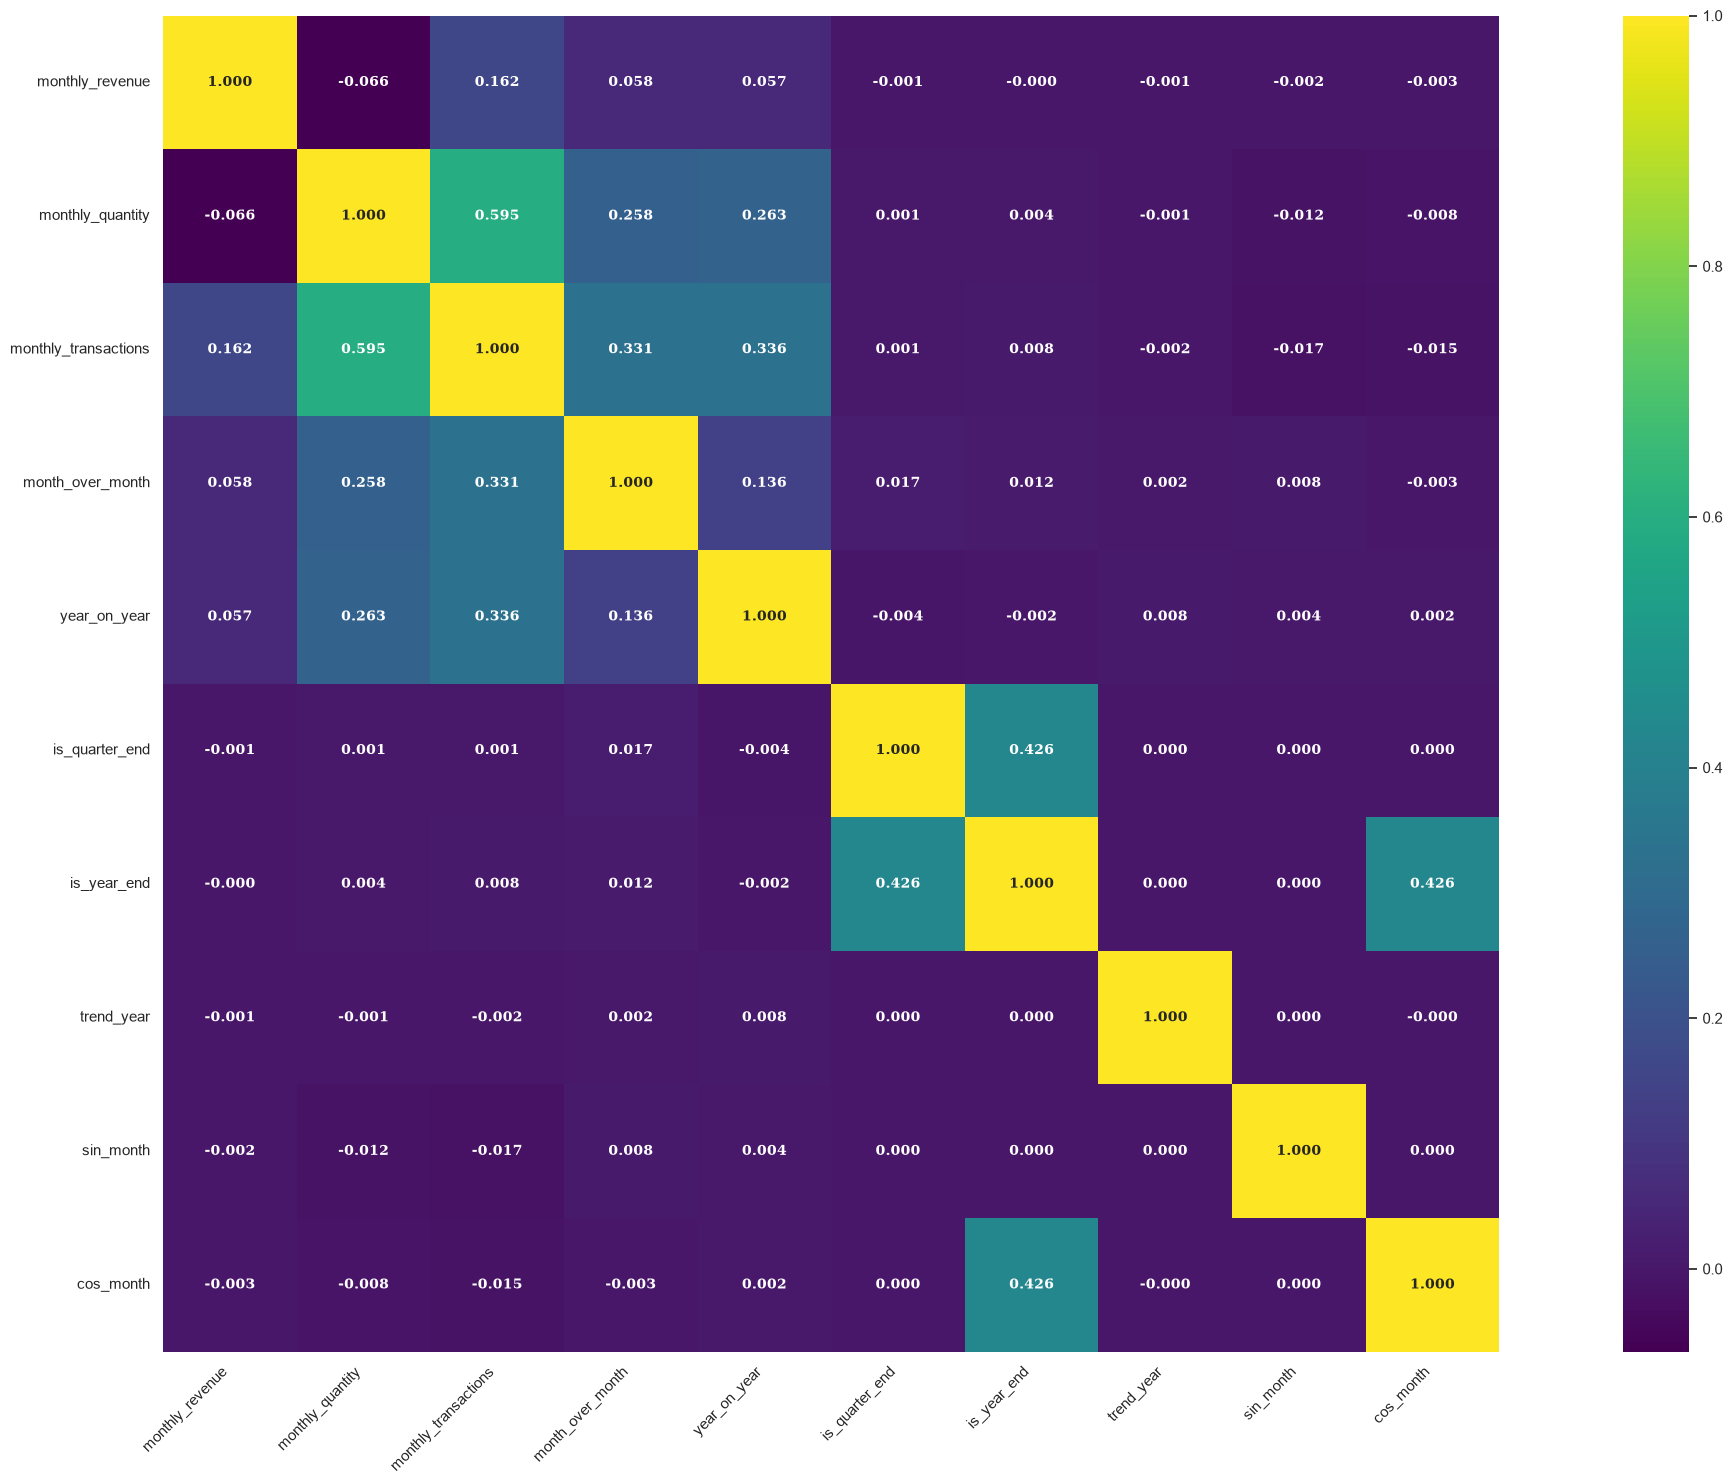

In [36]:
plt.figure(figsize=[25,15])
sns.heatmap(df[calendar_features].corr(), annot=True, fmt='.3f', square=True, cmap='viridis', annot_kws={'family': 'serif', 'size': 10, 'weight': 'bold'})
sns.set(font_scale=1)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

5) Product Features

In [37]:
product_features = ['monthly_revenue', 'monthly_quantity',
       'monthly_transactions', 'price_range', 'non_discounted_revenue', 'unique_customers', 'revenue_per_customer', 'units_per_customer',
       'category_revenue_share', 'category_unit_share', 'total_profit',
       'average_profit', 'market_share']

In [38]:
df[product_features].corr()

,monthly_revenue,monthly_quantity,monthly_transactions,price_range,non_discounted_revenue,unique_customers,revenue_per_customer,units_per_customer,category_revenue_share,category_unit_share,total_profit,average_profit,market_share
monthly_revenue,1.000000,-0.066119,0.161782,0.905823,0.546443,0.161614,0.914175,-0.188654,0.649685,0.277311,0.891523,0.812425,0.998767
monthly_quantity,-0.066119,1.000000,0.595159,-0.066410,-0.001289,0.594848,-0.151503,0.720744,0.018509,0.034852,-0.079279,-0.173458,-0.066679
monthly_transactions,0.161782,0.595159,1.000000,0.076661,0.071580,0.999679,-0.003728,-0.019729,0.297011,0.588926,0.179092,-0.002858,0.161279
price_range,0.905823,-0.066410,0.076661,1.000000,0.512590,0.076574,0.918614,-0.149775,0.630996,0.154812,0.803721,0.813937,0.906724
non_discounted_revenue,0.546443,-0.001289,0.071580,0.512590,1.000000,0.071523,0.504989,-0.053548,0.325127,0.117186,0.520113,0.485327,0.545129
unique_customers,0.161614,0.594848,0.999679,0.076574,0.071523,1.000000,-0.003890,-0.020378,0.296900,0.588804,0.178866,-0.002946,0.161112
revenue_per_customer,0.914175,-0.151503,-0.003728,0.918614,0.504989,-0.003890,1.000000,-0.194982,0.566681,0.170787,0.808702,0.886780,0.915336
units_per_customer,-0.188654,0.720744,-0.019729,-0.149775,-0.053548,-0.020378,-0.194982,1.000000,-0.176233,-0.351216,-0.213598,-0.221519,-0.189425
category_revenue_share,0.649685,0.018509,0.297011,0.630996,0.325127,0.296900,0.566681,-0.176233,1.000000,0.504802,0.640440,0.555085,0.651070
category_unit_share,0.277311,0.034852,0.588926,0.154812,0.117186,0.588804,0.170787,-0.351216,0.504802,1.000000,0.280467,0.165844,0.278386


In [39]:
product_features_corr = df[product_features].corr().stack().reset_index()
product_features_corr.columns = ['Feature A', 'Feature B', 'Correlation']
product_features_corr = product_features_corr[product_features_corr['Feature A'] != product_features_corr['Feature B']]

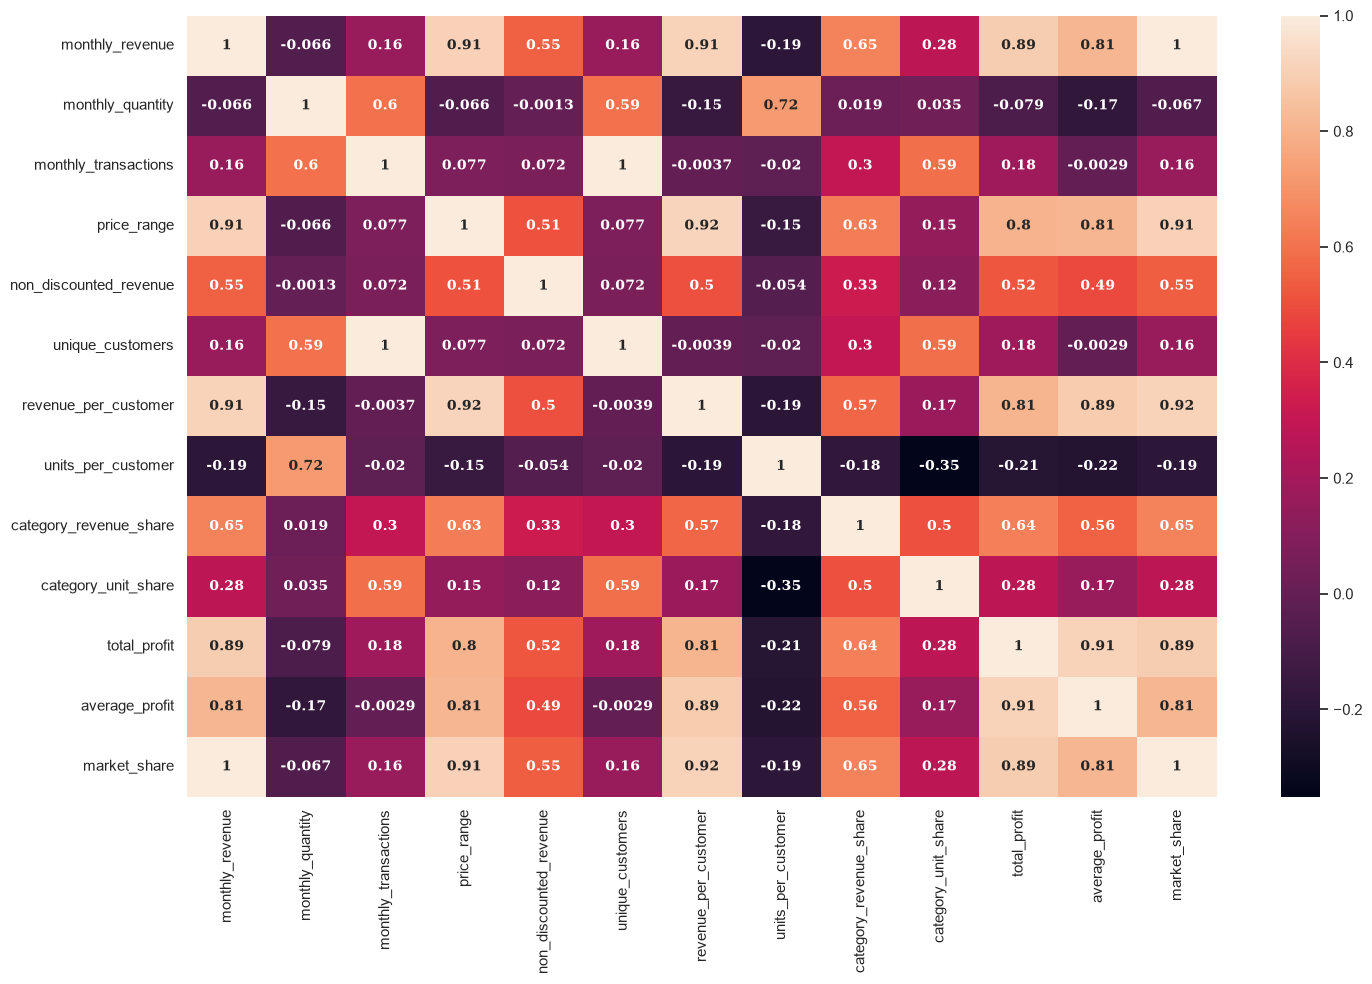

In [40]:
plt.figure(figsize=[15,10])
sns.heatmap(df[product_features].corr(), annot=True, annot_kws={'family': 'serif', 'size': 10, 'weight': 'bold'})
plt.tight_layout()
plt.show()

6) Customer Behaviour Features

In [56]:
customer_features = ['monthly_revenue', 'monthly_quantity',
       'monthly_transactions', 'price_range', 'non_discounted_revenue',
       'discounted_revenue', 'unique_customers', 'revenue_per_customer', 'units_per_customer',
       'category_revenue_share', 'category_unit_share', 'total_profit',
       'average_profit', 'market_share', 'lag_1_revenue','lag_1_quantity', 
       'lag_1_transactions', 'moving_avg_3_month', 'moving_avg_6_month',
       'moving_stdev_3_month', 'moving_stdev_6_month', 'momentum', 'month_over_month', 'year_on_year']

In [57]:
df[customer_features].corr()

,monthly_revenue,monthly_quantity,monthly_transactions,price_range,non_discounted_revenue,discounted_revenue,unique_customers,revenue_per_customer,units_per_customer,category_revenue_share,...,lag_1_revenue,lag_1_quantity,lag_1_transactions,moving_avg_3_month,moving_avg_6_month,moving_stdev_3_month,moving_stdev_6_month,momentum,month_over_month,year_on_year
monthly_revenue,1.000000,-0.066119,0.161782,0.905823,0.546443,0.992892,0.161614,0.914175,-0.188654,0.649685,...,0.819654,-0.155093,-0.004430,0.938975,0.924432,0.816339,0.869845,0.050426,0.058028,0.056772
monthly_quantity,-0.066119,1.000000,0.595159,-0.066410,-0.001289,-0.070600,0.594848,-0.151503,0.720744,0.018509,...,-0.155219,0.468698,0.003318,-0.133622,-0.151782,-0.125263,-0.146502,0.232313,0.257976,0.262900
monthly_transactions,0.161782,0.595159,1.000000,0.076661,0.071580,0.163024,0.999679,-0.003728,-0.019729,0.297011,...,-0.006082,0.002685,-0.000421,0.053891,0.024596,0.024526,0.009822,0.312991,0.330737,0.335969
price_range,0.905823,-0.066410,0.076661,1.000000,0.512590,0.896882,0.076574,0.918614,-0.149775,0.630996,...,0.847614,-0.110926,-0.003423,0.924205,0.927552,0.799030,0.874597,0.019289,0.022163,0.022050
non_discounted_revenue,0.546443,-0.001289,0.071580,0.512590,1.000000,0.442878,0.071523,0.504989,-0.053548,0.325127,...,0.438664,-0.047713,-0.003679,0.503001,0.493799,0.450514,0.472046,0.021291,0.031499,0.029255
discounted_revenue,0.992892,-0.070600,0.163024,0.896882,0.442878,1.000000,0.162851,0.906903,-0.194353,0.649315,...,0.814831,-0.159186,-0.004219,0.933376,0.918994,0.809611,0.863685,0.050930,0.057624,0.056588
unique_customers,0.161614,0.594848,0.999679,0.076574,0.071523,0.162851,1.000000,-0.003890,-0.020378,0.296900,...,-0.006110,0.002708,-0.000280,0.053822,0.024535,0.024397,0.009711,0.312808,0.330539,0.335936
revenue_per_customer,0.914175,-0.151503,-0.003728,0.918614,0.504989,0.906903,-0.003890,1.000000,-0.194982,0.566681,...,0.895682,-0.167393,-0.003118,0.959790,0.972334,0.848884,0.925274,0.000194,0.002698,0.001613
units_per_customer,-0.188654,0.720744,-0.019729,-0.149775,-0.053548,-0.194353,-0.020378,-0.194982,1.000000,-0.176233,...,-0.200472,0.598198,0.004490,-0.209689,-0.214906,-0.183575,-0.200723,0.051783,0.068276,0.070387
category_revenue_share,0.649685,0.018509,0.297011,0.630996,0.325127,0.649315,0.296900,0.566681,-0.176233,1.000000,...,0.502025,-0.166982,-0.002657,0.588159,0.572357,0.511031,0.540961,0.105768,0.113267,0.114546


In [58]:
customer_features_corr = df[customer_features].corr().stack().reset_index()
customer_features_corr.columns = ['Feature A', 'Feature B', 'Correlation']
customer_features_corr = customer_features_corr[customer_features_corr['Feature A'] != customer_features_corr['Feature B']]

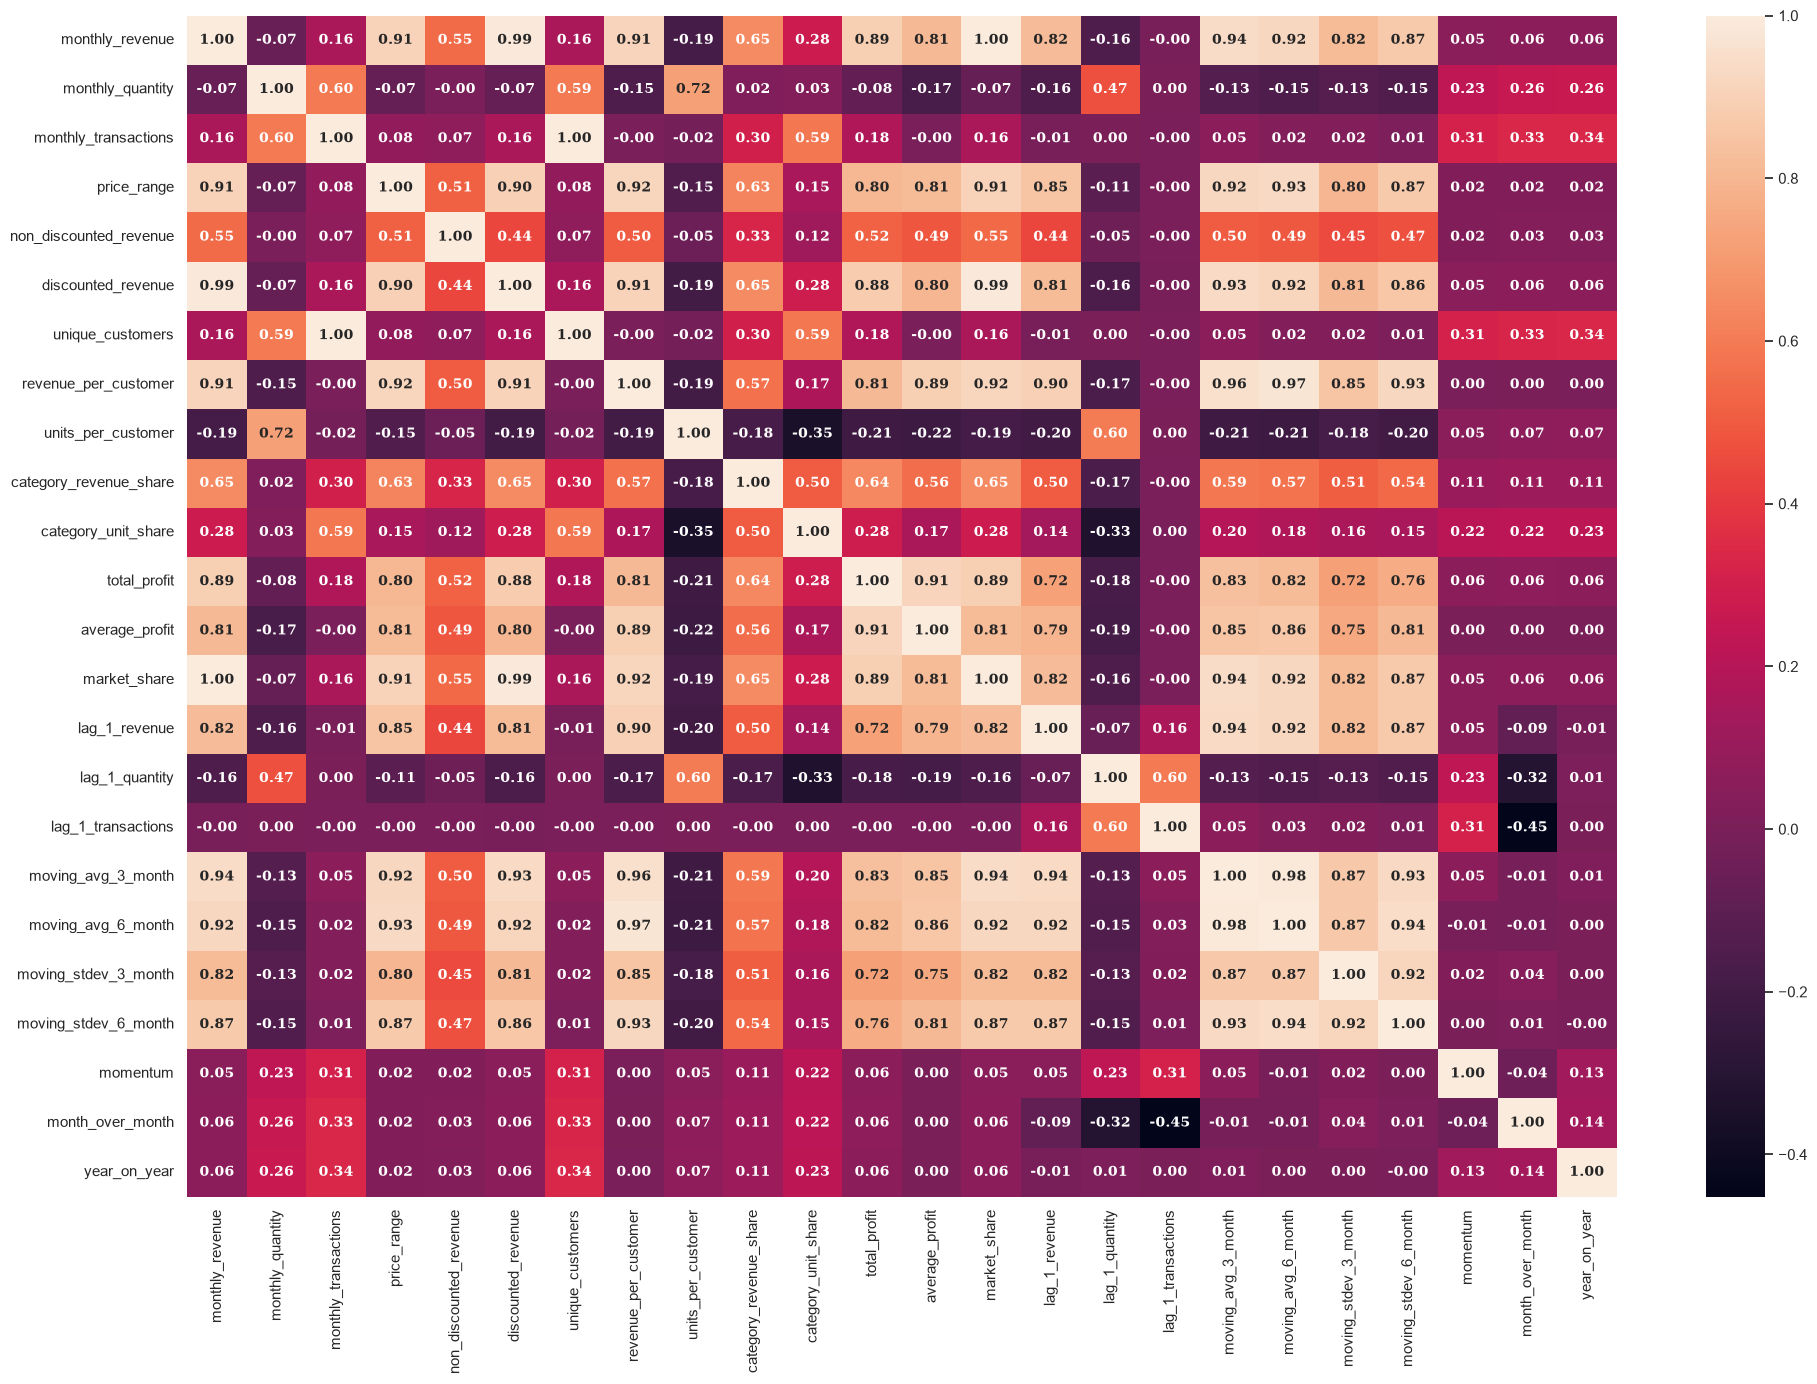

In [61]:
plt.figure(figsize=[20,14])
sns.heatmap(df[customer_features].corr(), annot=True, annot_kws={'family': 'serif', 'size': 10, 'weight': 'bold'}, fmt='.2f')
plt.tight_layout()
plt.show()

In [65]:
df['maximum_discount'].describe()

count    109009.000000
mean         16.130512
std           7.731164
min           0.000000
25%          10.000000
50%          14.000000
75%          23.000000
max          30.000000
Name: maximum_discount, dtype: float64

In [52]:
final_features = pd.concat([historical_features_corr, market_features_corr, price_and_discount_features_corr, calendar_features_corr,
                            product_features_corr, customer_features_corr], ignore_index=True)

In [53]:
final_features.shape

(1554, 3)

In [54]:
historical_features_corr

,Feature A,Feature B,Correlation
1,monthly_revenue,monthly_quantity,-0.066119
2,monthly_revenue,monthly_transactions,0.161782
3,monthly_revenue,lag_1_revenue,0.819654
4,monthly_revenue,lag_2_revenue,0.823809
5,monthly_revenue,lag_3_revenue,0.828857
...,...,...,...
435,momentum,moving_avg_3_month,0.054160
436,momentum,moving_avg_6_month,-0.009331
437,momentum,moving_avg_12_month,-0.007553
438,momentum,moving_stdev_3_month,0.023129


In [55]:
df[feature_cols].shape

(109009, 52)

In [66]:
df.shape

(109009, 56)

In [67]:
final_df = df[['product_id', 'year', 'month_number', 'monthly_revenue', 'monthly_quantity', 'monthly_transactions', 
               'lag_1_revenue', 'lag_2_revenue', 'lag_3_revenue', 'lag_12_revenue',
               'lag_1_quantity', 'lag_2_quantity', 'lag_3_quantity', 'lag_12_quantity',
               'lag_1_transactions', 'lag_2_transactions', 'lag_3_transactions', 'lag_12_transactions',
               'moving_avg_3_month', 'moving_avg_6_month', 'momentum', 
               'unique_customers', 'revenue_per_customer', 'units_per_customer', 'category_revenue_share', 'category_unit_share',
               'average_profit', 'market_share', 'average_discount_pct', 'pct_transactions_discount_gt_10', 'pct_transactions_discount_gt_15',
               'average_selling_price', 'price_range', 'discounted_quantity_sold', 
               'month_over_month', 'year_on_year', 'is_quarter_end', 'sin_month', 'cos_month', 'next_monthly_revenue']]

In [68]:
final_df.to_csv("../data/processed/final_ML_dataset.csv")